In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
ROOT = Path.cwd().parent

data_path = ROOT / "data" / "processed" / "ca1_features.parquet"

df = pd.read_parquet(data_path)


print("Shape:", df.shape)
print("Products:", df["item_id"].nunique())
print("Date range:", df["date"].min(), "to", df["date"].max())

Shape: (5832737, 25)
Products: 3049
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00


In [3]:
dates = np.sort(df["date"].unique())

validation_dates = dates[-56:-28]
test_dates = dates[-28:]

train_end = validation_dates[0]
validation_end = validation_dates[-1]
test_start = test_dates[0]

train_df = df[df["date"] < train_end].copy()
val_df = df[df["date"].isin(validation_dates)].copy()
test_df = df[df["date"].isin(test_dates)].copy()

print("Train history ends:", train_df["date"].max())
print("Validation:", validation_dates[0], "to", validation_dates[-1])
print("Test:", test_dates[0], "to", test_dates[-1])

print("\nRows")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train history ends: 2016-02-28 00:00:00
Validation: 2016-02-29T00:00:00.000000 to 2016-03-27T00:00:00.000000
Test: 2016-03-28T00:00:00.000000 to 2016-04-24T00:00:00.000000

Rows
Train: 5661993
Validation: 85372
Test: 85372


---
## Baseline 1 - Naive forecast 

In [4]:
def naive_forecast(history, horizon=28):
    last_value = history.iloc[-1]
    return np.repeat(last_value, horizon)

---
## Baseline 2 — Seasonal naive forecast

In [5]:
def seasonal_naive_forecast(history, horizon=28, season_length=7):
    last_season = history.iloc[-season_length:].to_numpy()

    repeats = int(np.ceil(horizon / season_length))
    return np.tile(last_season, repeats)[:horizon]

---
## Baseline 3 - Moving-average forecast 

In [6]:
def moving_average_forecast(history, horizon=28, window=7):
    mean_value = history.iloc[-window:].mean()
    return np.repeat(mean_value, horizon)

In [7]:
def generate_baseline_forecasts(df, forecast_dates):
    forecast_start = pd.Timestamp(forecast_dates[0])
    horizon = len(forecast_dates)

    history_df = df[df["date"] < forecast_start]

    actual_df = df[df["date"].isin(forecast_dates)][
        ["item_id", "date", "sales"]
    ].copy()

    forecasts = []

    for item_id, actual_group in actual_df.groupby("item_id", sort=False):
        history = (history_df.loc[history_df["item_id"] == item_id].sort_values("date")["sales"])

        if len(history) < 28:
            continue

        forecasts.append(
            pd.DataFrame({
                "item_id": item_id,
                "date": forecast_dates,
                "actual": actual_group.sort_values("date")["sales"].to_numpy(),
                "naive": naive_forecast(history, horizon),
                "seasonal_naive": seasonal_naive_forecast(history, horizon),
                "moving_average": moving_average_forecast(history, horizon),
            })
        )

    return pd.concat(forecasts, ignore_index=True)


val_forecasts = generate_baseline_forecasts(df, validation_dates)

print("Validation forecast shape:", val_forecasts.shape)
val_forecasts.head()

Validation forecast shape: (85372, 6)


,item_id,date,actual,naive,seasonal_naive,moving_average
0,FOODS_1_001,2016-02-29,1,0,0,0.142857
1,FOODS_1_001,2016-03-01,0,0,1,0.142857
2,FOODS_1_001,2016-03-02,1,0,0,0.142857
3,FOODS_1_001,2016-03-03,0,0,0,0.142857
4,FOODS_1_001,2016-03-04,0,0,0,0.142857


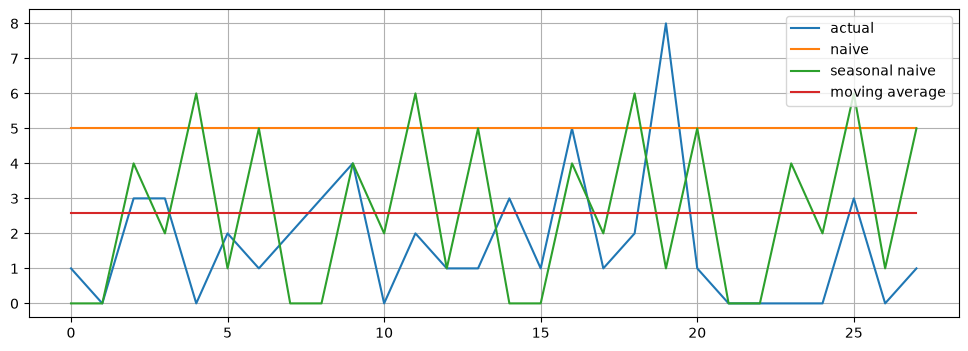

In [19]:
item = val_forecasts[val_forecasts['item_id']=='FOODS_1_006'].reset_index(drop = True)

plt.figure(figsize = (12, 4))
plt.plot(item.index, item['actual'], label = 'actual')
plt.plot(item.index, item['naive'], label = 'naive')
plt.plot(item.index, item['seasonal_naive'], label = 'seasonal naive')
plt.plot(item.index, item['moving_average'], label = 'moving average')
plt.legend()
plt.grid()

In [20]:
# Evaluate the baselines

from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_forecasts(forecasts, target_col="actual"):
    results = []

    actual = forecasts[target_col].to_numpy()

    for model in ["naive", "seasonal_naive", "moving_average"]:
        predicted = forecasts[model].to_numpy()

        mae = mean_absolute_error(actual, predicted)
        rmse = np.sqrt(mean_squared_error(actual, predicted))

        total_actual = np.sum(np.abs(actual))

        wape = (
            np.sum(np.abs(actual - predicted)) / total_actual * 100
            if total_actual != 0
            else np.nan
        )

        results.append({
            "model": model,
            "MAE": mae,
            "RMSE": rmse,
            "WAPE (%)": wape,
        })

    return (
        pd.DataFrame(results)
        .sort_values("WAPE (%)")
        .reset_index(drop=True)
    )


val_results = evaluate_forecasts(val_forecasts)
val_results


,model,MAE,RMSE,WAPE (%)
0,moving_average,1.114527,2.301854,75.970034
1,seasonal_naive,1.275266,2.818275,86.926529
2,naive,1.631964,3.557211,111.240279


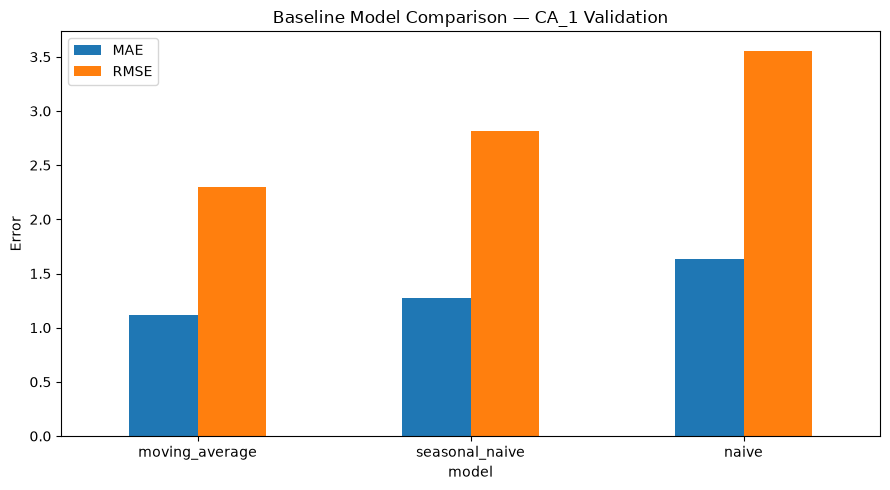

In [24]:
import matplotlib.pyplot as plt

val_results.set_index("model")[["MAE", "RMSE"]].plot(kind="bar", figsize=(9, 5))

plt.title("Baseline Model Comparison — CA_1 Validation")
plt.ylabel("Error")
# plt.xlabel("Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()